# Dynamic stopping

In [1]:
import glob
import matplotlib.pyplot as plt
import mne
import numpy as np
import os
import scipy as sp
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
import sklearn.metrics as metrics
import warnings

warnings.simplefilter(action='ignore', category=RuntimeWarning)
mne.set_log_level('WARNING')
np.random.seed(42)

## Exercise 1: Download, preprocess and inspect the data

#### Experimental setup:
In every trial the patient/user (from now on 'participant') has to focus on a single word from the set of 6 words. Each word/stimulus is played once per iteration. This means that an iteration consists of 6 words/stimuli, of which one is the target word. A sequence of 15 iterations, adding up to 90 stimuli, form one complete trial. The goal of a single trial is to determine what the target word is. This means that each iteration in a single trial shares the same target word. However, the order in which words are presented between iterations in a single trial may differ. To summarise, each trial has a single target word. Each trial consists of 15 iterations in which all 6 words are played once.

#### General EEG data information:
The data provided contains three file types: `.vhdr`, `.vmrk`, `.eeg`.  In the each `.vhdr` file you will find information about all recorded channels. Five of the channels listed are non-EEG channels:
* The EMG channel records an electromyogram. This is muscle activity.
* The GSR channel records the galvanic skin response. This is sweat gland activity which is indicative of stress levels and excitation.
* The Respi channel records respiration activity.
* The Pulse channel records the heart pulses by shining a red light on the finger and recording how much of it is reflected back.
* The Optic channel is an optical sensor focused on a portion of the screen that flashes every time an event happens in order to detect potential interference/delay between the time point the computer issues a stimulus and the time the stimulus is actually presented on the screen to the user.

Some of these channels can be used to remove artefacts from the EEG signal and better phase-locking the signals. For our experiment though they aren't relevant.

In the `.vhdr` files you will also find the resolution ( $\mu V$ steps) of each channel and the impedance (kOhm) of all channels, a higher impedance results in a higher noise level.

In each `.vmrk` you will find the event marker information. Each stimulus/event has an `event_id`. In our case, non-target words have event_ids $[101, 102, ..., 106]$. We have 6 different words. In every trial exactly 1 of them is in the target role. The target words are indicated by $[111,112, ..., 116]$. So, the last digit indicates the word id, the second digit indicates whether a stimulus is a target $(1)$ or non-target $(0)$.

Lastly, each `.eeg` file contains the recorded signals encoded in binary values and stored as integers. Increasing the value by 1 corresponds to a step value of 0.1 $\mu V$, which is the resolution denoted in the header (`.vhdr`) file.

Your task now is to:

1. Get the ERP data from Brightspace.
1. Run the code below to load and preprocess the data. 
1. (Optional) Inspect a single `.vhdr` and `.vmrk` file. You can open them with a text editor such as Notepad (or even VS code). Check where in the file the sampling resolution of the EEG channels is given. Has the frequency range been limited? If so, to what band? What is the sampling rate? Can you guess what was the intended temporal difference between 2 successive stimulus onsets? What could be the reason for this difference not being constant?
1. (Optional) Inspect the preprocessing functions we've provided and write down a short description of what each function does at every step. If you're unsure about some functions, look up the documentation of the relevant library.
    * In the creation of epochs, we decimate the sampling rate. Would this cause an aliasing problem? Why or why not?

In [2]:
# Preparations

def load_and_preprocess_raw(header_file, filter_band=(0.5, 16)):
    non_eeg_channels = ["EOGvu", "x_EMGl", "x_GSR", "x_Respi", "x_Pulse", "x_Optic"]
    raw = mne.io.read_raw_brainvision(header_file, misc=non_eeg_channels, preload=True)
    raw.set_montage("standard_1020")
    raw.filter(*filter_band, method="iir")
    raw.pick_types(eeg=True)
    return raw

def epoch_raw(raw, decimate=10):
    target_ids = list(range(111, 117))
    non_target_ids = list(range(101, 107))
    event_id = {f"Word_{i-110}/Target": i for i in target_ids}
    event_id.update({f"Word_{i-100}/NonTarget": i for i in non_target_ids})
    evs = mne.events_from_annotations(raw)[0]
    epoch = mne.Epochs(raw, events=evs, event_id=event_id, decim=decimate,
                       proj=False, tmax=1)
    return epoch

# Get the data path
data_dir = os.path.join(os.getcwd(), "data")
header_files = glob.glob(os.path.join(data_dir, "auditoryAphasia*.vhdr"))

# Load the data, preprocess and slice it into epochs
epochs = list()
for f in header_files:
    raw_data = load_and_preprocess_raw(f)
    epochs.append(epoch_raw(raw_data))

# Overwrite epochs list to save memory
epochs = mne.concatenate_epochs(epochs)

# Combine 6 epochs into a single iteration (6 stimuli together form a single iteration)
iterations = [epochs[i:i+6] for i in np.arange(0, epochs.events.shape[0],6)]

# Assert that each iteration contains exactly 1 Target
assert all([len(iteration["Target"]) == 1 for iteration in iterations]), "Number of targets in single iterations is unequal to 1."

# 15 iterations form a single trial
trials = [iterations[i:i+15] for i in np.arange(0,len(iterations),15)]

# Split trials into calibration set and online set
train_trials = trials[0:12] # data used to simulate the calibration part of the experiment.
test_trials = trials[12:] # data used to simulate the online experiment.

3. Yes, there seems to be a high cutoff of 250Hz for all channels, and also a low cutoff at 10Hz for x_EMGl. The sampling rate is 1kHz with an interval of 1 ms.
4. 

## Exercise 2: ERP plots
1. Plot the average ERP response of a word of your choice. Plot both or when the word is the target and when it is the non-target.
1. Can you spot the difference in average response when a target vs. non-target word is presented? 

**Hint**: See [MNE Epoch documentation](https://mne.tools/stable/generated/mne.Epochs.html) and [MNE Evoked documentation](https://mne.tools/stable/generated/mne.Evoked.html).

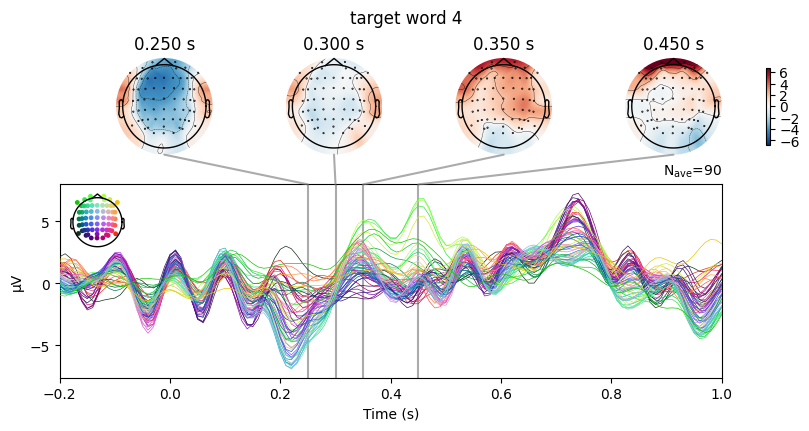

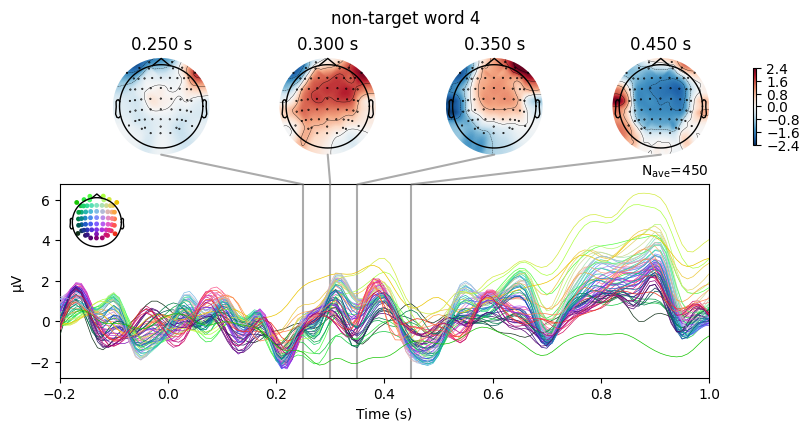

In [12]:
# Answer here

# 1: ERP plots
scalp_times = (0.25, 0.30, 0.35, 0.45)
i_word = 4
epochs[f'Word_{i_word}']["Target"].average().plot_joint(title=f'target word {i_word}', times=scalp_times);
epochs[f'Word_{i_word}']["NonTarget"].average().plot_joint(title=f'non-target word {i_word}', times=scalp_times);

## Exercise 3: Calibration
Below, we use 4 time intervals per channel, resulting in a feature dimensionality of $C=63$ channels and $T=4$ time intervals, for a total of $D=252$ features.
1. Inspect the shapes of `train_trials_` and `train_labels_`. What does every dimension mean?
1. Why do we reshape the trials?
1. Inspect how the classifier is trained and validated. Would it be a good idea to shuffle the data prior to making this training/validation split?
1. Can you find certain time intervals for `clf_ival_boundaries` that improve classification performance? **Hint**: look at the ERP plots.

/nix/store/0mxrnndssprpi6asmlnx3qwa30vlh8qv-bci-BKI323-env/lib/python3.11/site-packages/sklearn/metrics/_plot/roc_curve.py:189: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  self.ax_.legend(loc="lower right")


Text(0.5, 1.0, 'AUC-ROC Curve of the LDA classifier')

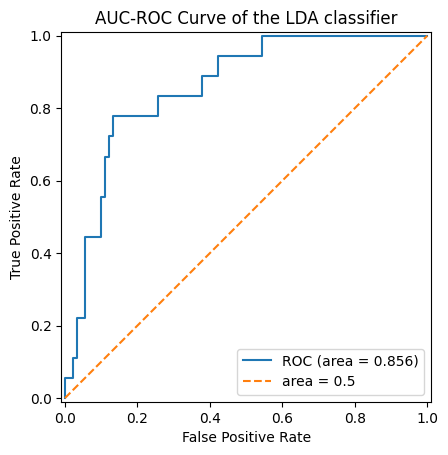

In [5]:
def get_jumping_means(epo, boundaries):
    shape_orig = epo.get_data().shape
    X = np.zeros((shape_orig[0], shape_orig[1], len(boundaries)-1))
    for i in range(len(boundaries)-1):
        idx = epo.time_as_index((boundaries[i], boundaries[i+1]))
        idx_range = list(range(idx[0], idx[1]))
        X[:,:,i] = epo.get_data()[:,:,idx_range].mean(axis=2)
    return X

# Specify the intervals over which to average the timepoints
clf_ival_boundaries = np.array([0.1, 0.2, 0.3, 0.4, 0.5])

# Extract relevant features
train_trials_ = np.array([[get_jumping_means(iteration, clf_ival_boundaries) 
                          for iteration in trial] 
                         for trial in train_trials])

# Reshape our data appropriately for feeding it into LDA
train_trials_ = np.reshape(train_trials_, (np.prod(train_trials_.shape[0:3]),-1)) 

# Extract labels
train_labels_ = np.array([[[[1 if event > 107 else 0] 
                           for event in iteration.events[:,2]] 
                          for iteration in trial] 
                         for trial in train_trials]).flatten()

# Split the training data into training and validation data
X_train, X_valid, y_train, y_valid = train_test_split(train_trials_, train_labels_, test_size=0.1, shuffle=False)

# Train a classifier on the training data
clf = LDA().fit(X_train, y_train)

# Evaluate the classifier on validation data
fpr, tpr, thresholds = metrics.roc_curve(y_valid, clf.decision_function(X_valid))
auc_fig = metrics.RocCurveDisplay(fpr=fpr, tpr = tpr)
auc_fig.plot()
plt.plot([0, 1],[0,1], '--')
plt.legend(['ROC (area = %0.3f)' % metrics.auc(fpr, tpr), 'area = 0.5'], loc="lower right")
plt.title("AUC-ROC Curve of the LDA classifier")


In [6]:
# Answer here

## Exercise 4: Dynamic stopping with Höhne's method

We will simulate an online experiment using the offline dataset. To properly do so, you would have to treat each stimulus (epoch) as if it were just recorded. Normally, this means you would have to apply all the preprocessing steps (spectral filtering, downsampling,  etc.). We already did that while loading the offline data. All that is left is extracting the features by averaging the time interval using the `get_jumping_means()` function. 

Some information about the variables:
- `test_word_targets` contains the target word id ($[1,2, ..,6]$) per trial. These should **only** be used to quantify the performance.
- `test_labels` contains whether the presented word was a target (1) or a non-target (0). 
- `test_words` contains the word id ($[1,2, ..,6]$) per stimulus/word presentation. 

1. Inspect the code given below. In this code the classifier predicts the signed distance to the decision boundary, given a single presented word. You will build on top of this code, so make sure you understand the three variables listed above.

1. **Condition A: no dynamic stopping.** Predict (using the provided classifier `clf`) the target words per trial, using the entire trial information. In other words, keep track of the **signed distances** to the decision hyperplane per word id throughout the entire trial to make a single prediction about the target word after all 15 iterations. Report your prediction accuracy. 
**NOTE**: The order in which words are presented differs per iteration in a trial. Also note that the classifier tried to learn a decision hyperplane such that targets have a positive signed distance to the hyperplane, and non-targets have a negative signed distance to the hyperplane.

1.  **Condition B: dynamic stopping.** Predict (using the provided classifier `clf`) the target words per trial while using a dynamic stopping procedure (Höhne's method). Perform a [(Welch's) t-test](https://en.wikipedia.org/wiki/Welch%27s_t-test) (look for the approriate Scipy function) per iteration to see whether you can stop the trial early. Make sure to first gather at least a few iterations before you start checking whether you can stop the trial early. You can decide on the p-value and the minimum number of iterations you wish to use. 

1. Report the average accuracy and average number of iterations per trial when using the dynamic stopping procedure with this p-value. Also convert the average number of iterations per trial to the average duration of a trial in seconds (using the sampling frequency).
    
1. Visualise:
    * The trade-off between accuracy and the p-value threshold.
    * The trade-off between the average time (s) of a trial and the p-value threshold. 
    * The trade-off between accuracy and the average time (s) of a trial.

You can visualise this by repeating 3.4 for a range of p-value threshold values. Make use of the p-value thresholds in the range of [0.001,0.5] with a sufficiently small step size to yield a somewhat smooth plot. 


/nix/store/0mxrnndssprpi6asmlnx3qwa30vlh8qv-bci-BKI323-env/lib/python3.11/site-packages/sklearn/metrics/_plot/roc_curve.py:189: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  self.ax_.legend(loc="lower right")


Text(0.5, 1.0, 'AUC-ROC Curve of the LDA classifier [online]')

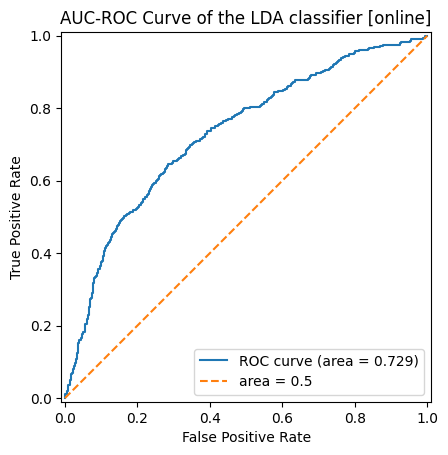

In [7]:
# The target word per trial
test_word_targets = np.array([trial[0]["Target"].events[:,2][0] % 10 for trial in test_trials]) 

# The location of the target word in the sequence of 6 stimuli per iteration. Note that the order of stimuli differs per iteration
test_labels = np.array([[[[1 if event > 107 else 0][0] for event in iteration.events[:,2]] for iteration in trial] for trial in test_trials]) 

# The word ID sequence that is presented per iteration. Note that the order of the presented words differs between iterations
test_words = np.array([[iteration.events[:,2]%10 for iteration in trial] for trial in test_trials]) 

# 4.1: Predict target/non-target per stimulus
signed_distances = np.zeros(test_words.shape)
for t, trial in enumerate(test_trials):
    for i, iteration in enumerate(trial):
        for s, stimulus in enumerate(iteration):
            # Compute signed distance of stimulus to decision boundary
            signed_distances[t, i, s] = clf.decision_function(get_jumping_means(iteration[s], clf_ival_boundaries).flatten().reshape(1,-1))[0] 

fpr, tpr, thresholds = metrics.roc_curve(test_labels.flatten(), signed_distances.flatten()) 
auc_fig = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr)
auc_fig.plot()
plt.plot([0, 1],[0,1], '--')
plt.legend(['ROC curve (area = %0.3f)' % metrics.auc(fpr, tpr), 'area = 0.5'], loc="lower right")
plt.title("AUC-ROC Curve of the LDA classifier [online]")


In [8]:
# Answer here for 4.2 (Condition A, no dynamic stopping)

In [9]:
# Answer here for 4.3 (Condition B, dynamic stopping)

In [10]:
# Answer here for 4.4 (Average accuracy and average duration)

In [11]:
# Answer here for 4.5 (Visualisation of the trade-offs)